# 04 — Market Distribution

Measure return distribution, skewness, kurtosis, quantiles and tails.


In [1]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [2]:
# Cell: Import Distribution Modules
import pandas as pd

from src.data.loaders import read_parquet, save_parquet
from src.features.returns import add_returns
from src.features.distribution import add_rolling_distribution_stats


In [3]:
# Cell: Build Distribution Features
clean = read_parquet("data/processed/clean_daily_ohlcv.parquet")
features = add_returns(clean)
features = add_rolling_distribution_stats(features, return_col="return_1d", window=60)
features.shape


(718709, 25)

In [4]:
# Cell: Summarize Distribution By Symbol
summary = (
    features.groupby("symbol").agg(
        mean_return=("return_1d", "mean"),
        median_return=("return_1d", "median"),
        skew_60d=("dist_skew_60d", "last"),
        kurt_60d=("dist_kurt_60d", "last"),
        tail_ratio_60d=("tail_ratio_60d", "last"),
    )
    .sort_values("tail_ratio_60d", ascending=False)
)
summary


,mean_return,median_return,skew_60d,kurt_60d,tail_ratio_60d
symbol,,,,,
KDC,0.000747,0.000000,0.116776,6.174913,3.128802
EVS,0.000667,0.000000,1.339895,2.640452,2.603758
STB,0.001495,0.001412,1.363666,2.148925,2.550642
ABW,0.000311,0.000000,0.764592,0.904098,2.473899
HII,0.000354,0.000000,0.990203,1.726590,2.399375
...,...,...,...,...,...
TCM,0.000680,0.000000,-0.976799,12.530905,0.327905
BCE,0.000371,0.000000,-1.602397,3.274345,0.300668
THG,0.000470,0.000000,-0.805441,1.443816,0.270500


In [5]:
# Cell: Save Distribution Outputs
# Notebook-only scratch output -- not read by any production script (confirmed
# via grep, docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md NV1). Kept out of
# data/processed/ on purpose so re-running this notebook by hand can never
# collide with scripts/generate_features.py's production output (see NV1 fix
# for 05/06_market_regime.ipynb in the same report).
save_parquet(features, "notebooks/outputs/stock_features_distribution.parquet")
features[["symbol", "date", "return_1d", "dist_skew_60d", "dist_kurt_60d", "tail_ratio_60d"]].tail(20)


,symbol,date,return_1d,dist_skew_60d,dist_kurt_60d,tail_ratio_60d
718689,YEG,2026-06-25,0.069429,1.630687,4.264391,1.765252
718690,YEG,2026-06-26,0.013613,1.590342,4.080465,1.765252
718691,YEG,2026-06-29,-0.039256,1.355158,3.827784,1.564019
718692,YEG,2026-06-30,0.023656,1.259071,3.426377,1.564019
718693,YEG,2026-07-01,-0.009454,1.261162,3.405038,1.564019
718694,YEG,2026-07-02,-0.011665,1.267177,3.448161,1.564019
718695,YEG,2026-07-03,-0.010730,1.298261,3.460498,1.564019
718696,YEG,2026-07-06,-0.020607,1.380464,3.870642,1.564019
718697,YEG,2026-07-07,-0.011074,1.380144,3.859720,1.564019
718698,YEG,2026-07-08,0.013438,1.427322,4.549935,1.121531


## Market Distribution Visualizations

The following sections plot the return distributions, rolling statistics, and historical dynamics to help visualize market distribution regimes.

In [6]:
# Cell: Setup Visualizations and Styles
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Set styling using custom rcParams
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 150,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": ":"
})


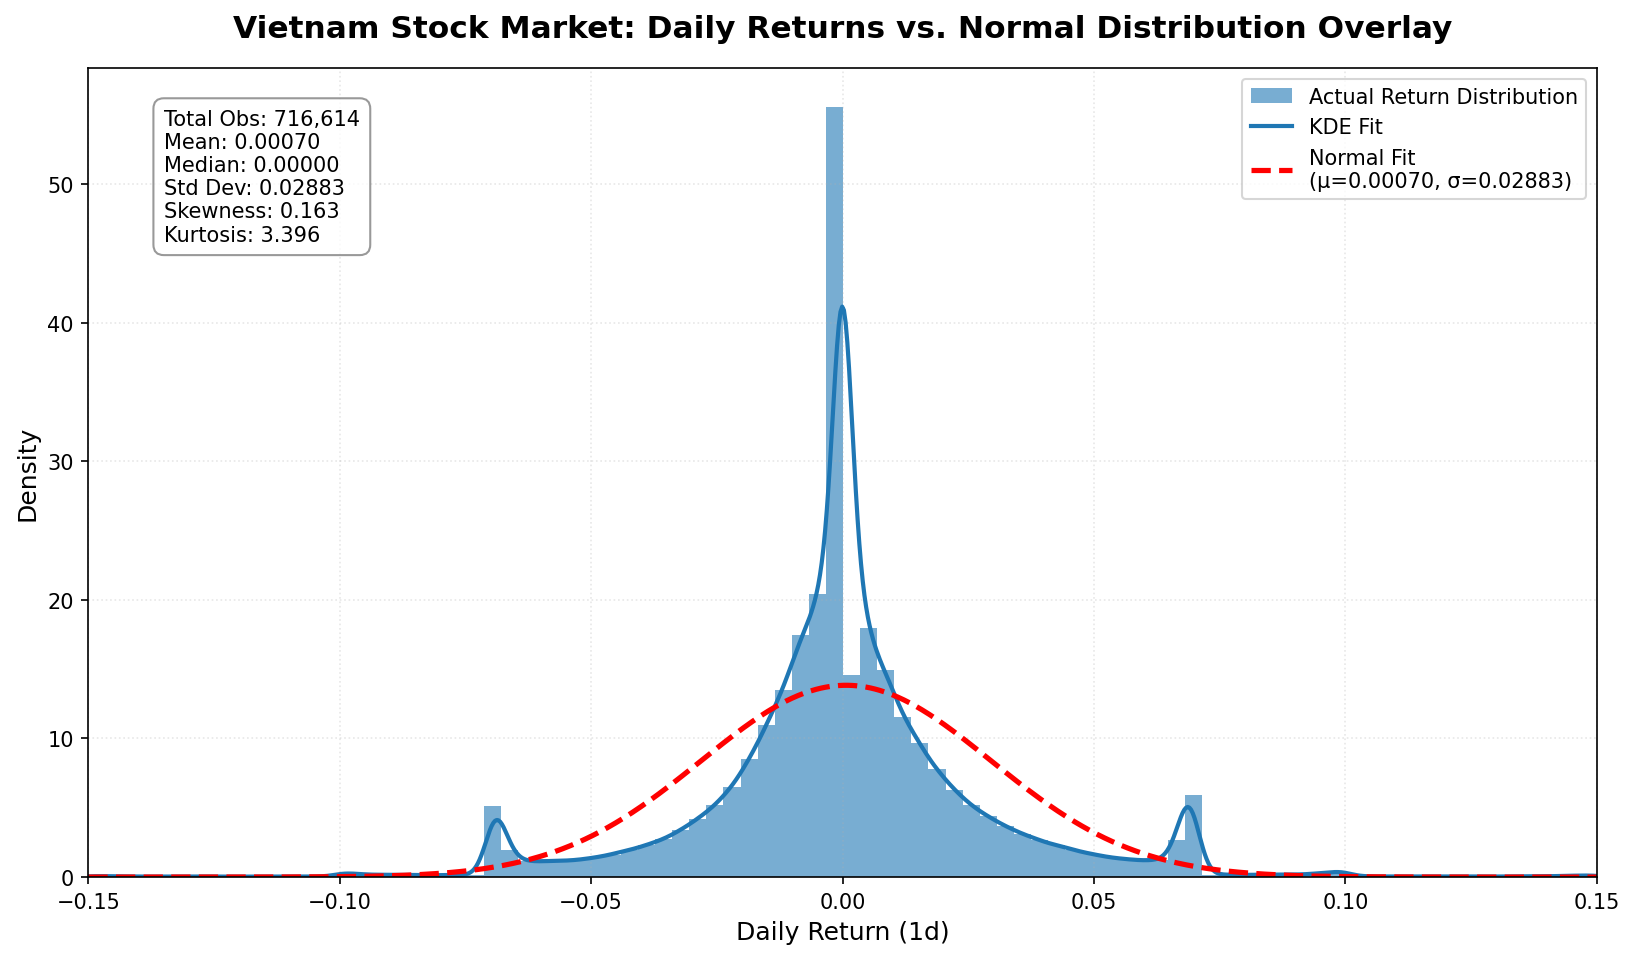

In [7]:
# Cell: Plot 1 - Market-Wide Daily Return Distribution vs. Normal Distribution Overlay
clean_returns = features["return_1d"].dropna()

# Calculate statistics
mean_ret = clean_returns.mean()
std_ret = clean_returns.std()
skew_ret = clean_returns.skew()
kurt_ret = clean_returns.kurt()  # excess kurtosis
median_ret = clean_returns.median()

# Plot histogram
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.hist(clean_returns, bins=100, density=True, color="#1f77b4", alpha=0.6, label="Actual Return Distribution")

# Fit KDE
try:
    kde = stats.gaussian_kde(clean_returns)
    x_kde = np.linspace(clean_returns.min(), clean_returns.max(), 1000)
    ax.plot(x_kde, kde(x_kde), color="#1f77b4", linewidth=2, label="KDE Fit")
except Exception:
    pass

# Restrict x range slightly for visualization if it stretches too far due to extreme tails
xmin, xmax = ax.get_xlim()
xmin = max(xmin, -0.15)
xmax = min(xmax, 0.15)
ax.set_xlim(xmin, xmax)

# Generate normal curve
x = np.linspace(xmin, xmax, 1000)
p = stats.norm.pdf(x, mean_ret, std_ret)
ax.plot(x, p, "r--", linewidth=2.5, label=f"Normal Fit\n(μ={mean_ret:.5f}, σ={std_ret:.5f})")

# Title and Labels
ax.set_title("Vietnam Stock Market: Daily Returns vs. Normal Distribution Overlay", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Daily Return (1d)", fontsize=12)
ax.set_ylabel("Density", fontsize=12)

# Text box with stats
stats_text = (
    f"Total Obs: {len(clean_returns):,}\n"
    f"Mean: {mean_ret:.5f}\n"
    f"Median: {median_ret:.5f}\n"
    f"Std Dev: {std_ret:.5f}\n"
    f"Skewness: {skew_ret:.3f}\n"
    f"Kurtosis: {kurt_ret:.3f}"
)
props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='gray')
ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=10, verticalalignment='top', bbox=props)

ax.legend(loc="upper right", fontsize=10)
plt.tight_layout()
plt.show()


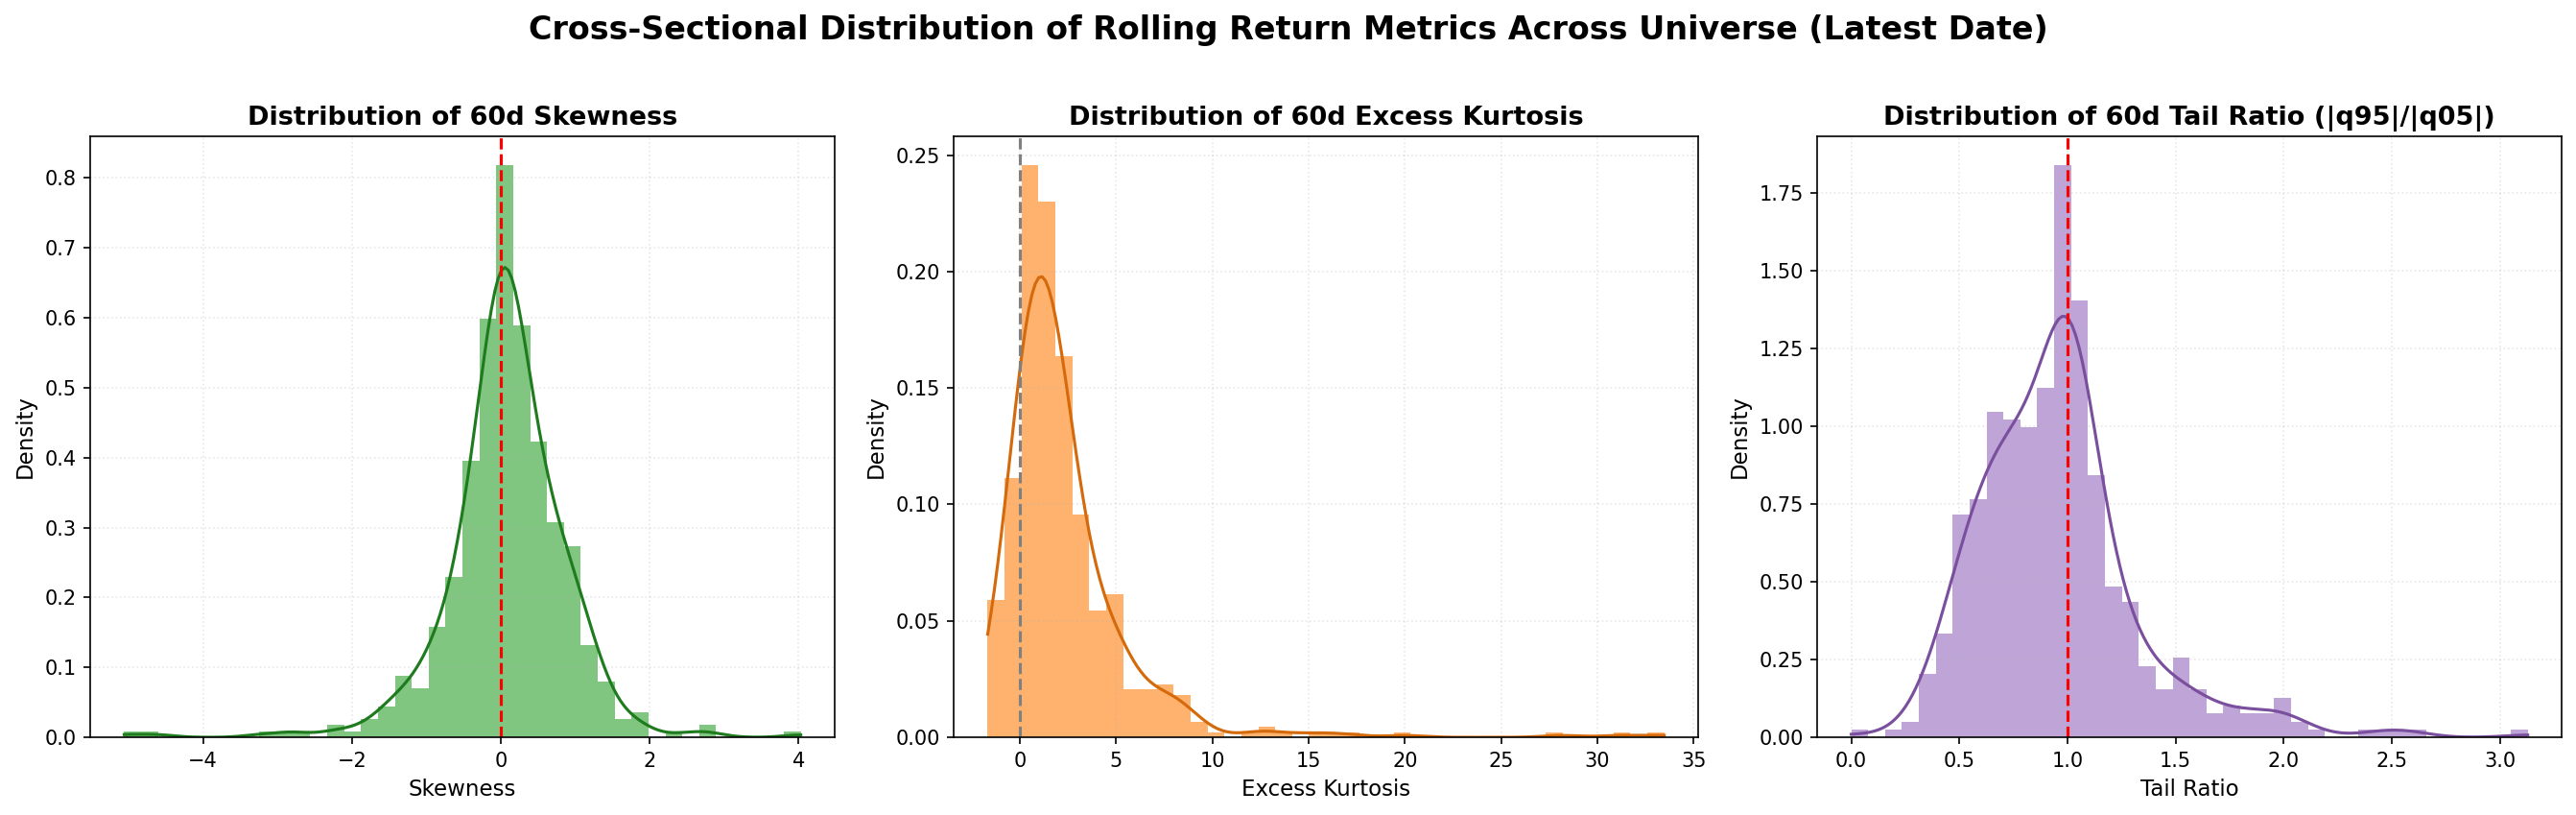

In [8]:
# Cell: Plot 2 - Cross-Sectional Distribution of Stats Across Symbols (Latest Date)
# Get the latest row for each symbol to examine current cross-sectional distribution
latest_stats = features.sort_values("date").groupby("symbol").last().reset_index()

# Filter out symbols that don't have rolling stats
latest_stats = latest_stats.dropna(subset=["dist_skew_60d", "dist_kurt_60d", "tail_ratio_60d"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Subplot A: Rolling Skewness
axes[0].hist(latest_stats["dist_skew_60d"], bins=40, density=True, color="#2ca02c", alpha=0.6)
try:
    kde_skew = stats.gaussian_kde(latest_stats["dist_skew_60d"])
    x_skew = np.linspace(latest_stats["dist_skew_60d"].min(), latest_stats["dist_skew_60d"].max(), 200)
    axes[0].plot(x_skew, kde_skew(x_skew), color="#1e7b1e", linewidth=1.5)
except:
    pass
axes[0].axvline(0, color="red", linestyle="--", linewidth=1.5)
axes[0].set_title("Distribution of 60d Skewness", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Skewness", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)

# Subplot B: Rolling Kurtosis (Excess)
axes[1].hist(latest_stats["dist_kurt_60d"], bins=40, density=True, color="#ff7f0e", alpha=0.6)
try:
    kde_kurt = stats.gaussian_kde(latest_stats["dist_kurt_60d"])
    x_kurt = np.linspace(latest_stats["dist_kurt_60d"].min(), latest_stats["dist_kurt_60d"].max(), 200)
    axes[1].plot(x_kurt, kde_kurt(x_kurt), color="#d46a0b", linewidth=1.5)
except:
    pass
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1.5)
axes[1].set_title("Distribution of 60d Excess Kurtosis", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Excess Kurtosis", fontsize=11)
axes[1].set_ylabel("Density", fontsize=11)

# Subplot C: Tail Ratio
axes[2].hist(latest_stats["tail_ratio_60d"], bins=40, density=True, color="#9467bd", alpha=0.6)
try:
    kde_tail = stats.gaussian_kde(latest_stats["tail_ratio_60d"])
    x_tail = np.linspace(latest_stats["tail_ratio_60d"].min(), latest_stats["tail_ratio_60d"].max(), 200)
    axes[2].plot(x_tail, kde_tail(x_tail), color="#7a4f9e", linewidth=1.5)
except:
    pass
axes[2].axvline(1.0, color="red", linestyle="--", linewidth=1.5)
axes[2].set_title("Distribution of 60d Tail Ratio (|q95|/|q05|)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Tail Ratio", fontsize=11)
axes[2].set_ylabel("Density", fontsize=11)

plt.suptitle("Cross-Sectional Distribution of Rolling Return Metrics Across Universe (Latest Date)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


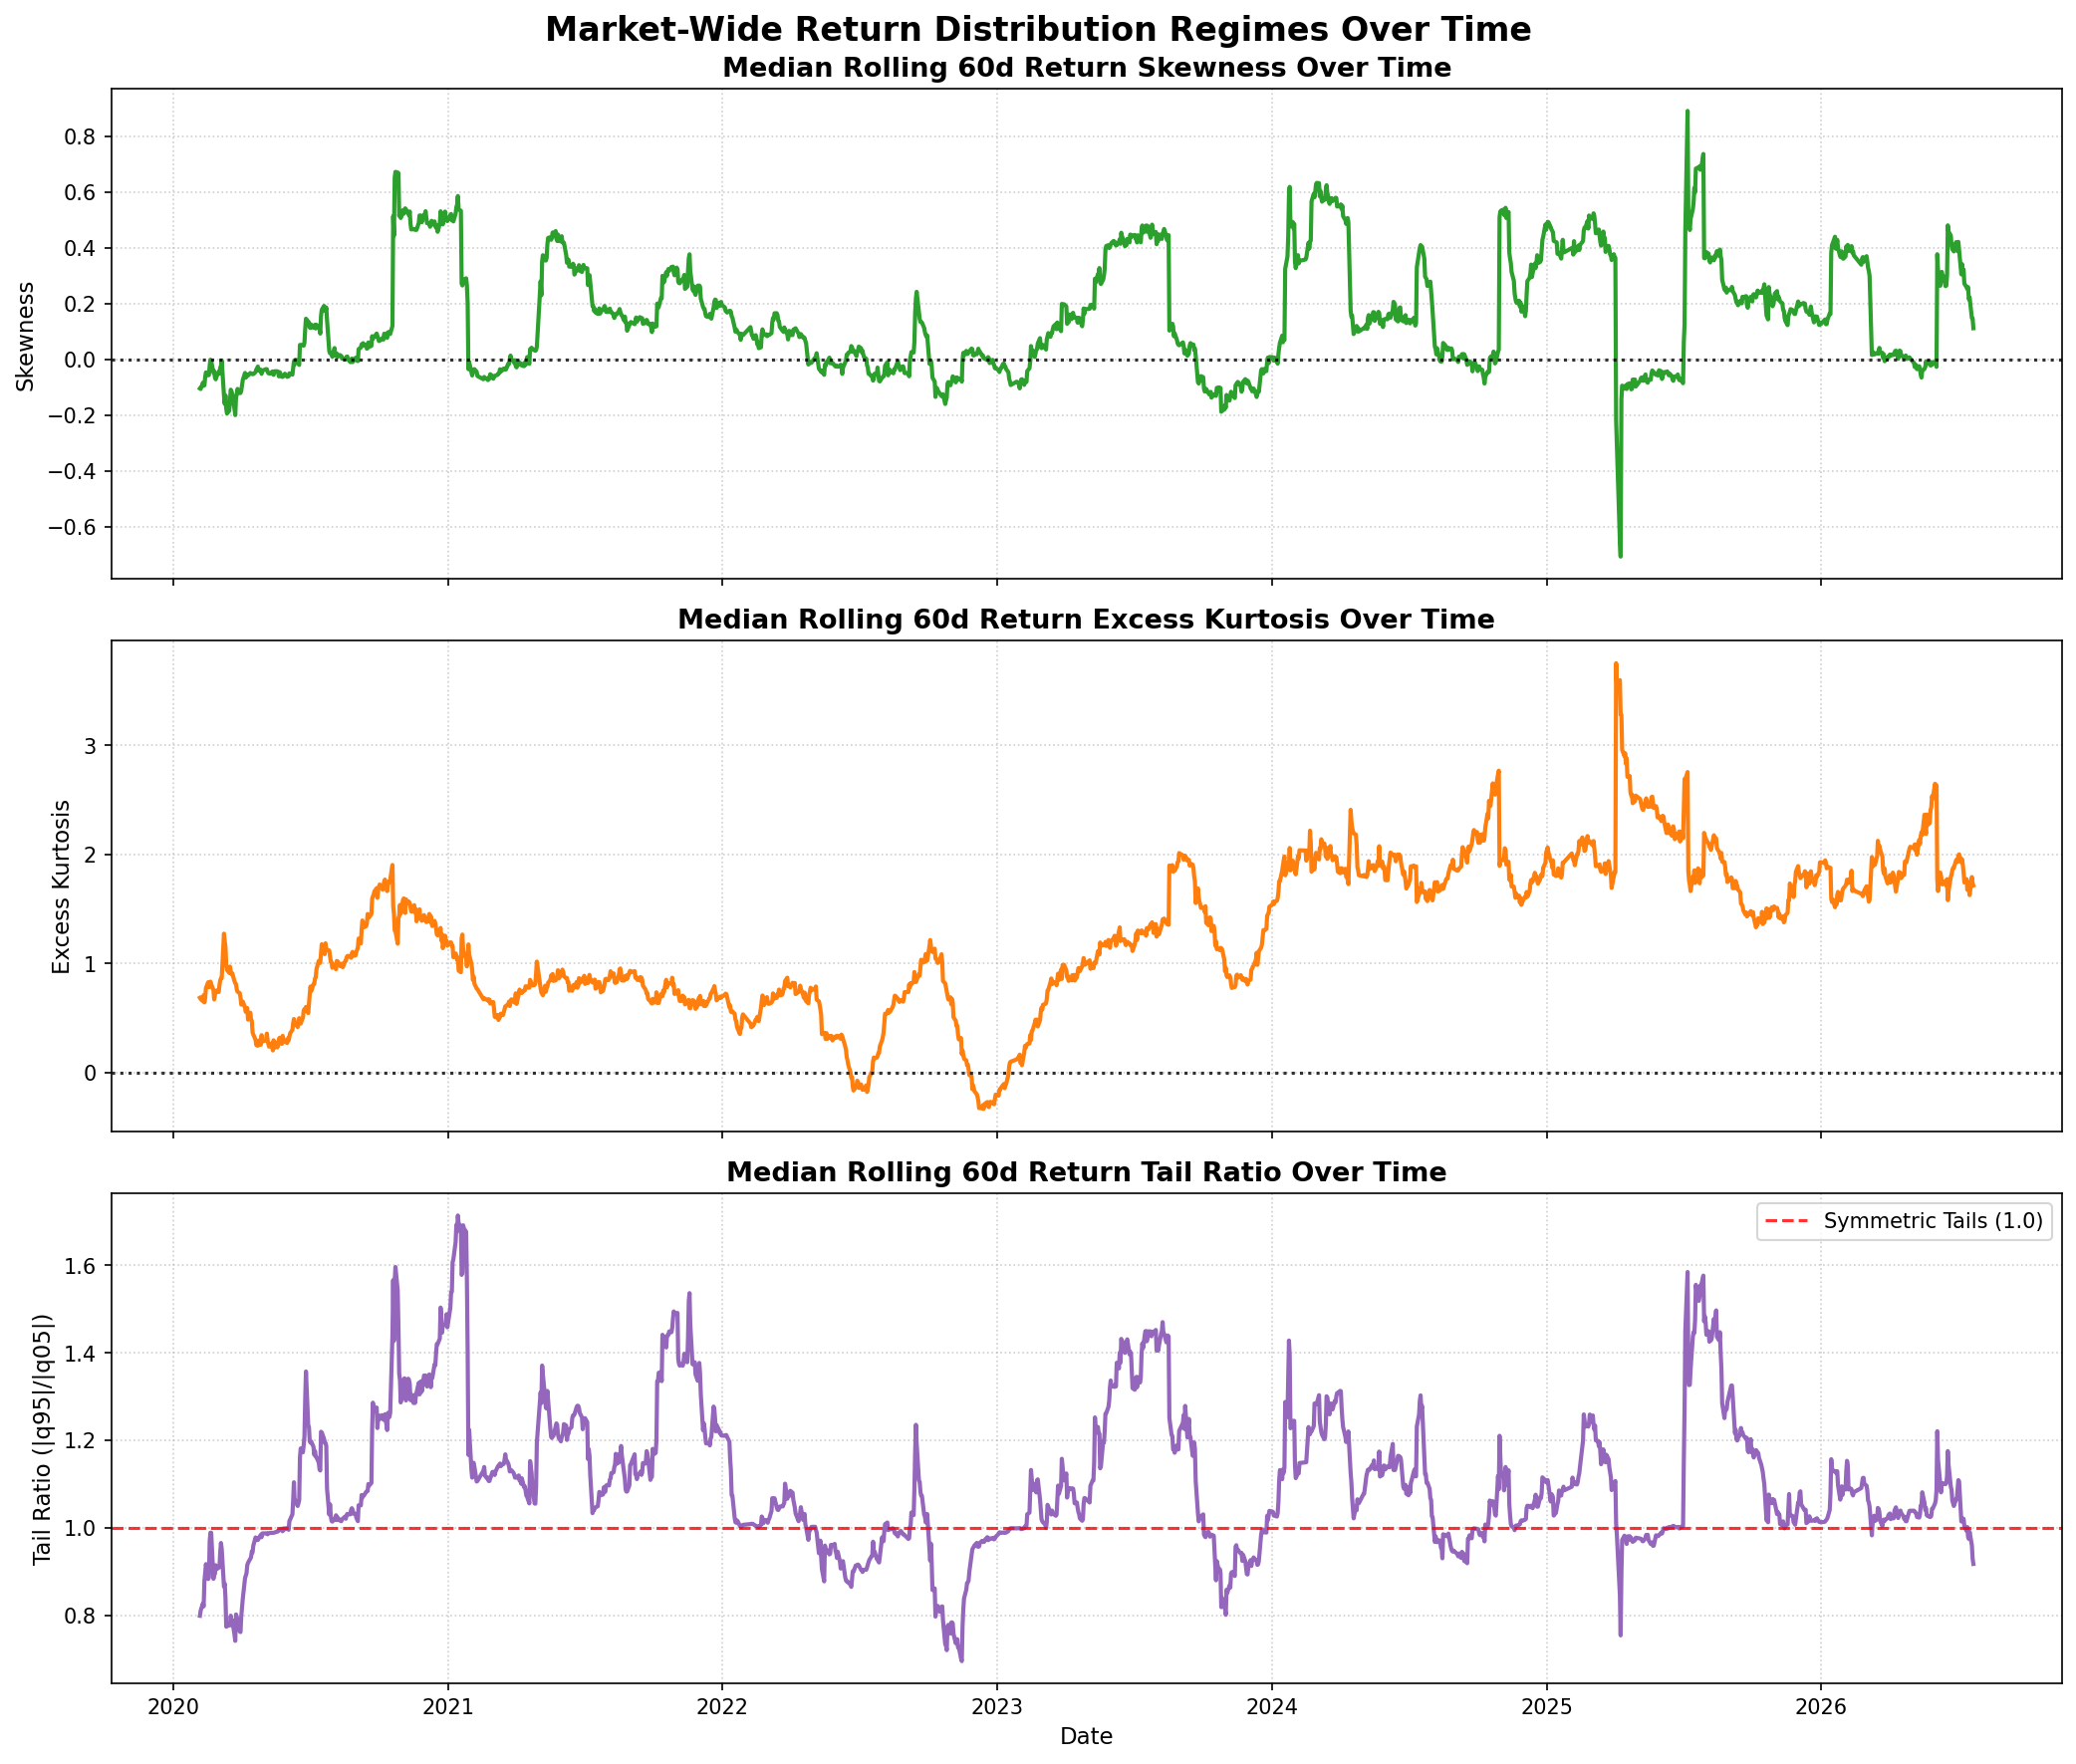

In [9]:
# Cell: Plot 3 - Time Series of Market-Wide Aggregated Distribution Stats
# Group by date and calculate median statistics to represent the general market state
market_time_series = features.groupby("date").agg(
    median_skew=("dist_skew_60d", "median"),
    median_kurt=("dist_kurt_60d", "median"),
    median_tail_ratio=("tail_ratio_60d", "median")
).reset_index()

# Convert date to datetime for better plotting
market_time_series["date"] = pd.to_datetime(market_time_series["date"])

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Subplot 1: Skewness over time
axes[0].plot(market_time_series["date"], market_time_series["median_skew"], color="#2ca02c", linewidth=2)
axes[0].axhline(0, color="black", linestyle=":", alpha=0.8)
axes[0].set_title("Median Rolling 60d Return Skewness Over Time", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Skewness", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Subplot 2: Kurtosis over time
axes[1].plot(market_time_series["date"], market_time_series["median_kurt"], color="#ff7f0e", linewidth=2)
axes[1].axhline(0, color="black", linestyle=":", alpha=0.8)
axes[1].set_title("Median Rolling 60d Return Excess Kurtosis Over Time", fontsize=13, fontweight="bold")
axes[1].set_ylabel("Excess Kurtosis", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)

# Subplot 3: Tail Ratio over time
axes[2].plot(market_time_series["date"], market_time_series["median_tail_ratio"], color="#9467bd", linewidth=2)
axes[2].axhline(1.0, color="red", linestyle="--", alpha=0.8, label="Symmetric Tails (1.0)")
axes[2].set_title("Median Rolling 60d Return Tail Ratio Over Time", fontsize=13, fontweight="bold")
axes[2].set_ylabel("Tail Ratio (|q95|/|q05|)", fontsize=11)
axes[2].set_xlabel("Date", fontsize=11)
axes[2].legend(loc="upper right")
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.suptitle("Market-Wide Return Distribution Regimes Over Time", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


High Tail Ratio Symbol: KDC (Tail Ratio: 3.13)
Low Tail Ratio Symbol: GIL (Tail Ratio: 0.19)


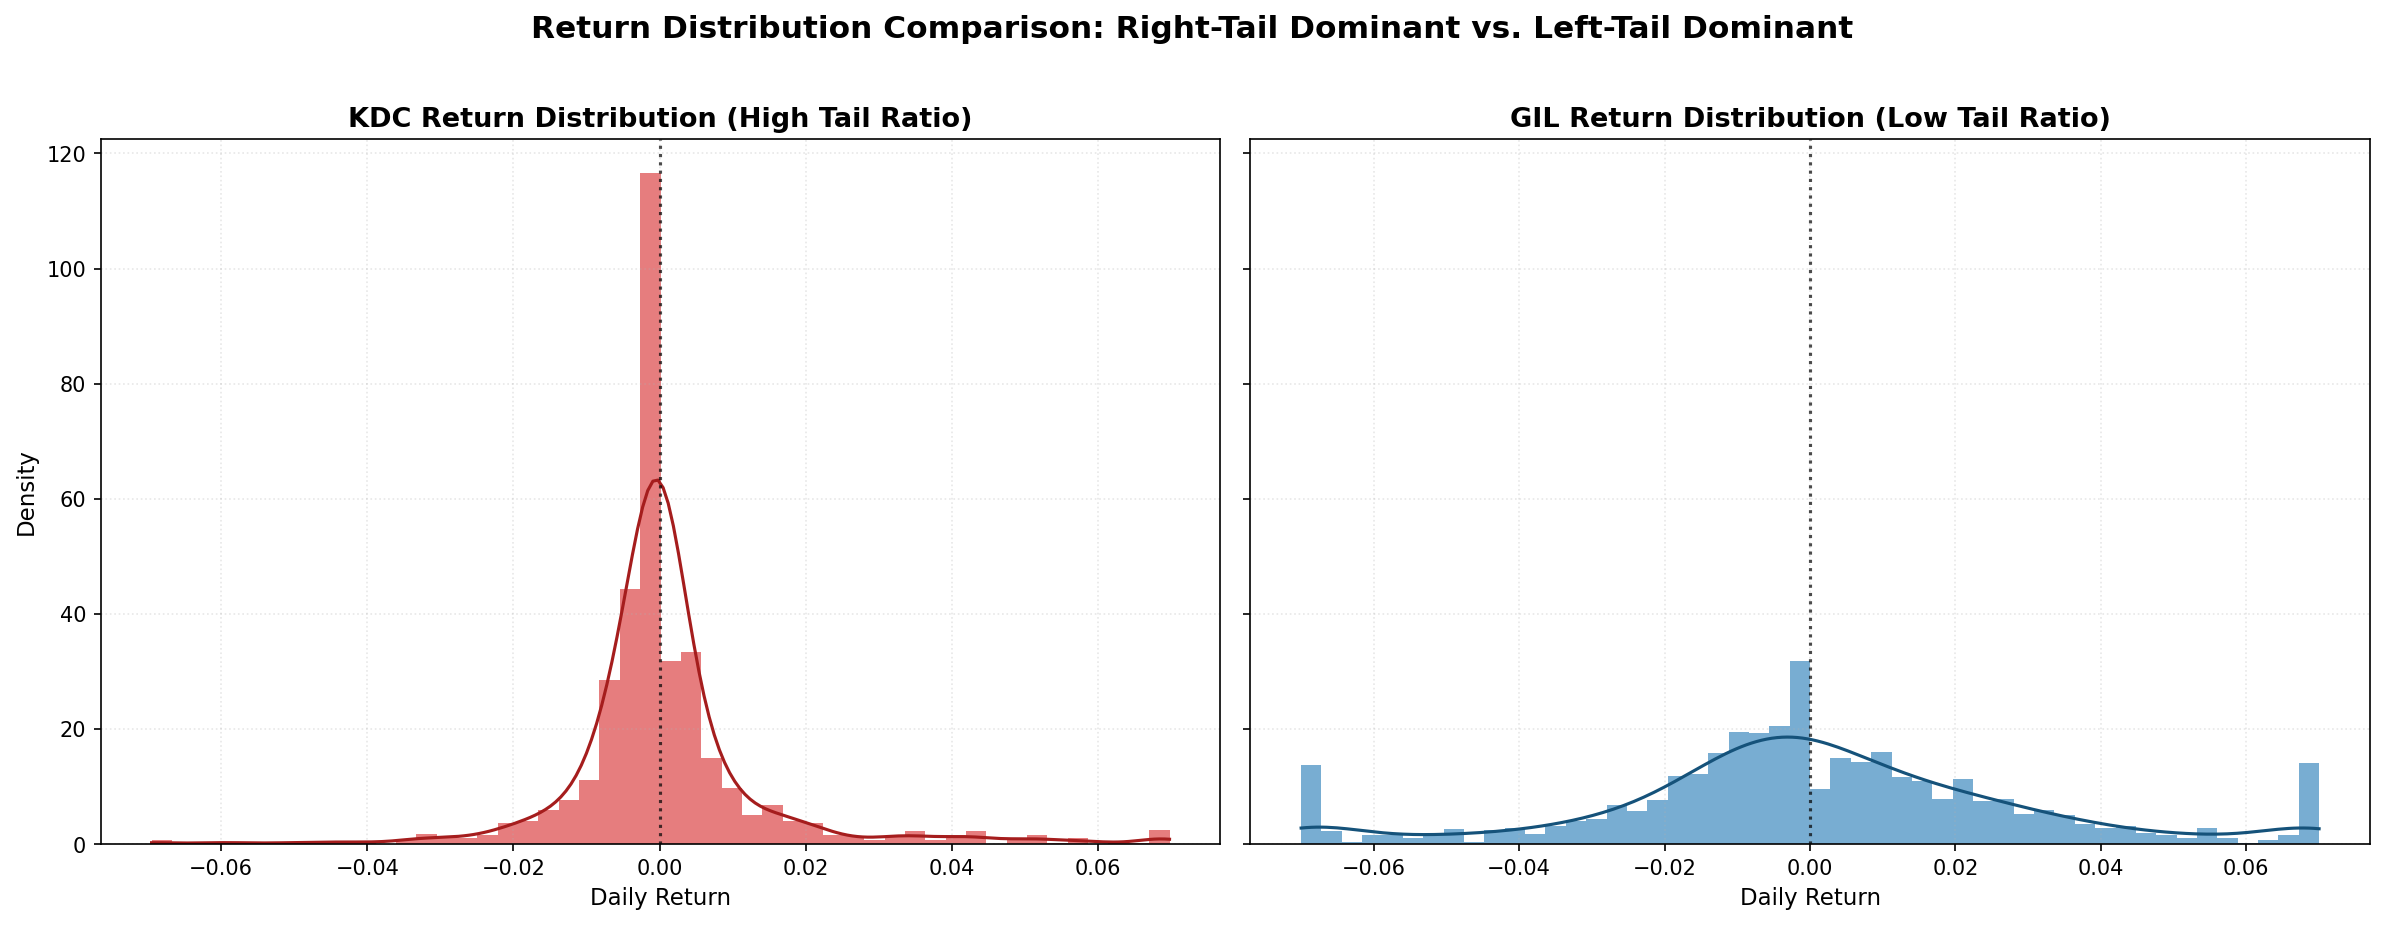

In [10]:
# Cell: Plot 4 - Visual Comparison of Extreme Tail-Risk Symbols
# Find symbols with high and low tail ratios at the latest date
latest_stats_valid = latest_stats[latest_stats["tail_ratio_60d"] > 0]
if not latest_stats_valid.empty:
    high_tail_symbol = latest_stats_valid.sort_values("tail_ratio_60d", ascending=False).iloc[0]["symbol"]
    low_tail_symbol = latest_stats_valid.sort_values("tail_ratio_60d", ascending=True).iloc[0]["symbol"]
    
    print(f"High Tail Ratio Symbol: {high_tail_symbol} (Tail Ratio: {latest_stats[latest_stats['symbol'] == high_tail_symbol]['tail_ratio_60d'].values[0]:.2f})")
    print(f"Low Tail Ratio Symbol: {low_tail_symbol} (Tail Ratio: {latest_stats[latest_stats['symbol'] == low_tail_symbol]['tail_ratio_60d'].values[0]:.2f})")
    
    # Get returns for these symbols
    returns_high = features[features["symbol"] == high_tail_symbol]["return_1d"].dropna()
    returns_low = features[features["symbol"] == low_tail_symbol]["return_1d"].dropna()
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    # High Tail plot
    axes[0].hist(returns_high, bins=50, density=True, color="#d62728", alpha=0.6, label=high_tail_symbol)
    try:
        kde_h = stats.gaussian_kde(returns_high)
        x_h = np.linspace(returns_high.min(), returns_high.max(), 200)
        axes[0].plot(x_h, kde_h(x_h), color="#a51d1d", linewidth=1.5)
    except:
        pass
    axes[0].axvline(0, color="black", linestyle=":", alpha=0.7)
    axes[0].set_title(f"{high_tail_symbol} Return Distribution (High Tail Ratio)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Daily Return", fontsize=11)
    axes[0].set_ylabel("Density", fontsize=11)

    # Low Tail plot
    axes[1].hist(returns_low, bins=50, density=True, color="#1f77b4", alpha=0.6, label=low_tail_symbol)
    try:
        kde_l = stats.gaussian_kde(returns_low)
        x_l = np.linspace(returns_low.min(), returns_low.max(), 200)
        axes[1].plot(x_l, kde_l(x_l), color="#15527a", linewidth=1.5)
    except:
        pass
    axes[1].axvline(0, color="black", linestyle=":", alpha=0.7)
    axes[1].set_title(f"{low_tail_symbol} Return Distribution (Low Tail Ratio)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Daily Return", fontsize=11)

    plt.suptitle("Return Distribution Comparison: Right-Tail Dominant vs. Left-Tail Dominant", fontsize=15, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No valid tail ratio data found for comparison.")
